# تحلیل داده‌های اخبار فارسی

**هدف:** بررسی کیفیت داده، تحلیل توزیع خبرها بر اساس منبع و برچسب‌های موجود، و پردازش مقدماتی متن فارسی.

> نکته روش‌شناختی: فایل `main_news.csv` ستون تاریخ ندارد؛ بنابراین تحلیل زمانی انجام نمی‌شود. فایل `category_news.csv` نیز کلید اتصالِ قابل‌تأییدی به رکوردهای `main_news.csv` در اختیار نمی‌گذارد؛ در نتیجه برای جلوگیری از نسبت‌دادن دسته‌های نادرست، آن را به اخبار وصل نمی‌کنیم. دسته‌بندی موضوعی این تحلیل، یک **گروه‌بندی تقریبی و شفاف‌شده از ستون `tags`** است و با دسته‌بندی رسمی دیتاست یکسان فرض نمی‌شود.

کدها با مسیرهای نسبی نوشته شده‌اند؛ فایل‌های CSV را کنار این نوت‌بوک قرار دهید.

## 1. واردکردن کتابخانه‌ها و تنظیمات

In [1]:
from pathlib import Path
import re
import html
from urllib.parse import unquote
from collections import Counter
import sys
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

try:
    import arabic_reshaper
    from bidi.algorithm import get_display
    RTL_AVAILABLE = True
except ImportError:
    RTL_AVAILABLE = False


def rtl(text):
    text = str(text)
    if RTL_AVAILABLE:
        return get_display(arabic_reshaper.reshape(text))
    fallback = {
        "تعداد خبرها به تفکیک منبع": "News Count by Source",
        "تعداد خبر": "Number of Articles",
        "منبع": "Source",
        "توزیع گروه‌های موضوعی تقریبی بر اساس tags": "Approximate Topic Groups",
        "گروه موضوعی": "Topic Group",
        "توزیع تعداد واژه‌های خبر (تا صدک 95)": "Word Count Distribution",
        "تعداد واژه": "Word Count",
        "میانه تعداد واژه به تفکیک گروه موضوعی": "Median Word Count by Topic",
        "میانه تعداد واژه": "Median Words",
        "۲۰ واژه پرتکرار پس از حذف واژه‌های عمومی": "Top 20 Words",
        "تعداد تکرار": "Frequency",
        "واژه": "Term",
    }
    return fallback.get(text, text)


def fix_persian_axis(ax):
    ax.set_title(rtl(ax.get_title()))
    ax.set_xlabel(rtl(ax.get_xlabel()))
    ax.set_ylabel(rtl(ax.get_ylabel()))
    ax.figure.canvas.draw()
    for axis, get_ticks, get_labels in [
        (ax.xaxis, ax.get_xticks, ax.get_xticklabels),
        (ax.yaxis, ax.get_yticks, ax.get_yticklabels),
    ]:
        ticks = get_ticks()
        labels = [rtl(label.get_text()) for label in get_labels()]
        if len(ticks) == len(labels):
            axis.set_major_locator(FixedLocator(ticks))
            axis.set_major_formatter(FixedFormatter(labels))
    return ax


try:
    from hazm import Normalizer, word_tokenize
    HAZM_AVAILABLE = True
    normalizer = Normalizer()
except ImportError:
    HAZM_AVAILABLE = False
    normalizer = None
    def word_tokenize(text):
        return re.findall(r"[\u0600-\u06FF]+|[A-Za-z]+|\d+", text)


_BASE_STOPWORDS = """
از با به در برای که و یا را این آن یک نیز اما اگر تا بر
است هستند بود بودند باشد شده شود شدن کرده کنند کرد کردند گفت گفته
کند شد دارد دارند داشت داشتند
می نمی خواهد خواهند توان تواند بتواند بتوانند نمایند
وی او آنها آنان ما شما من تو
خود خودش خودشان خودمان خودم خودت
های ها
هم نه بله پس چون چرا وقتی اکنون امروز دیروز فردا
بسیار بیشتر کمتر میان بعد قبل روی زیر بالای درباره همچنین تنها دیگر همان هرگز همیشه
همه چیز کسی چیزی
تر ترین
ای اینکه آنکه آن‌که این‌که
دو یک سه چهار پنج شش هفت هشت نه ده صد هزار میلیون میلیارد
کشور سال روز نفر اعلام مردم دولت
شده_است کرده_است کرده_اند بوده_است
"""

_EXTRA_GENERAL = """
اند باید قرار مورد داد داده دهد دهیم دهد دهند
کرد کردن کرده‌اند کرده‌ام کرده‌ای کردم کردی کردیم کردید
شد شدن شده‌اند شده‌ام شده‌ای شدم شدی شدیم شدید
بود بودن بوده‌اند بوده‌ام بوده‌ای بودم بودی بودیم بودید
دار داشتن داشته داشته داشته‌اند داشته‌ام داشته‌ای داشتم داشتی داشتیم داشتید
بین پیش پس نیز ولی اما هم
دهد دهند دهم دهیم دهی دهید
کنم کنی کنیم کنید کنند
شدیم شدید شوند شوم شوی شویم شوید
گشت گشته گردیده
مثل مانند قبیل نوع انواع
مورد موارد ضمن باب
طبق طبقِ برابر
اول دوم سوم چهارم پنجم ششم هفتم هشتم نهم دهم
بسیار زیادی کمی
داخل خارج نزد کنار
حتی فقط صرفاً
الان حال حاضر
باید بایست بایستی
نمی‌شود نمی‌کند نمی‌توان
آنجا اینجا آنکه اینکه
گزارش رئیس سازمان وزارت ادامه انجام کار گذشته
مسئول مدیر معاون دبیر سخنگو
بررسی پیگیری تشریح توضیح اعلام
هفته ماهانه سالانه روزانه
بوده بسیاری جمله گرفته منتشر متحده شمار
توجه رعایت هستیم صورت اشاره
"""

PERSIAN_STOPWORDS = set((_BASE_STOPWORDS + "\n" + _EXTRA_GENERAL).split())
PERSIAN_STOPWORDS = {w.strip() for w in PERSIAN_STOPWORDS if w.strip()}

TFIDF_BOILERPLATE = {
    "دویچه", "وله", "دویچه_وله", "ایسنا", "تسنیم",
    "رادیو", "فردا", "رادیوفردا", "خبرگزاری",
    "بپیوندید", "کانال", "تلگرام", "اینستاگرام", "دنبال", "کنید",
    "انتهای", "پیام", "کلیک", "لینک", "مطلب", "بخوانید",
    "نظر", "دیدگاه", "کامنت",
    "افزود", "اظهار", "بیان", "گفت", "گوید",
}


def filter_tokens(tokens, stopwords=None):
    if stopwords is None:
        stopwords = PERSIAN_STOPWORDS
    result = []
    for token in tokens:
        parts = token.split("_") if "_" in token else [token]
        for part in parts:
            part = part.strip()
            if (len(part) > 1
                and not part.isdigit()
                and not all(c.isdigit() for c in part)
                and part not in stopwords):
                result.append(part)
    return result


DATA_PATH = Path("main_news.csv")
CATEGORY_PATH = Path("category_news.csv")
OUTPUT_DIR = Path("outputs")
CHART_DIR = OUTPUT_DIR / "charts"
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.family"] = ["Tahoma", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("Hazm available:", HAZM_AVAILABLE)
print("Persian chart shaping available:", RTL_AVAILABLE)
print("Chart folder:", CHART_DIR.resolve())
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print(f"تعداد stopwordها: {len(PERSIAN_STOPWORDS):,}")

Hazm available: True
Persian chart shaping available: True
Chart folder: C:\Users\ASUS\Desktop\persian_news_analysis_project_updated\persian_news_analysis_project\outputs\charts
Python: 3.9.2
Pandas: 2.3.3
Matplotlib: 3.9.4
تعداد stopwordها: 255


In [ ]:
category_news_df = None
category_integration_status = "اجرا نشده"

if CATEGORY_PATH.exists():
    category_news_df = pd.read_csv(CATEGORY_PATH)
    print(f"فایل category_news.csv بارگذاری شد: {category_news_df.shape[0]:,} ردیف، {category_news_df.shape[1]} ستون")
    print("ستون‌ها:", category_news_df.columns.tolist())
    display(category_news_df.head())

    overlap_report = []

    # بررسی هم‌پوشانی بر اساس link
    if "link" in category_news_df.columns and "link" in df_raw.columns:
        main_links = set(df_raw["link"].dropna().astype(str).str.strip())
        cat_links = set(category_news_df["link"].dropna().astype(str).str.strip())
        common = main_links & cat_links
        pct = len(common) / max(len(main_links), 1) * 100
        overlap_report.append({
            "کلید اتصال": "link",
            "تعداد main": len(main_links),
            "تعداد category": len(cat_links),
            "تعداد مشترک": len(common),
            "درصد هم‌پوشانی": round(pct, 2),
        })

    # بررسی هم‌پوشانی بر اساس title
    if "title" in category_news_df.columns and "title" in df_raw.columns:
        main_titles = set(df_raw["title"].dropna().astype(str).str.strip())
        cat_titles = set(category_news_df["title"].dropna().astype(str).str.strip())
        common = main_titles & cat_titles
        pct = len(common) / max(len(main_titles), 1) * 100
        overlap_report.append({
            "کلید اتصال": "title",
            "تعداد main": len(main_titles),
            "تعداد category": len(cat_titles),
            "تعداد مشترک": len(common),
            "درصد هم‌پوشانی": round(pct, 2),
        })

    if overlap_report:
        report_df = pd.DataFrame(overlap_report).sort_values("درصد هم‌پوشانی", ascending=False)
        display(report_df)
        best = report_df.iloc[0]
        if best["درصد هم‌پوشانی"] >= 50:
            category_integration_status = f"موفق بر اساس {best['کلید اتصال']} ({best['درصد هم‌پوشانی']}%)"
            print(f"ادغام انجام می‌شود: {category_integration_status}")
        else:
            category_integration_status = (
                f"ناموفق: بیشترین هم‌پوشانی {best['درصد هم‌پوشانی']}% "
                f"({best['کلید اتصال']}) زیر آستانه ۵۰٪"
            )
            print(f"{category_integration_status}")
            print("نتیجه: ادغام انجام نمی‌شود؛ تحلیل موضوعی بر پایه tags ادامه می‌یابد.")
    else:
        category_integration_status = "ناموفق: ستون مشترک برای اتصال وجود ندارد"
        print(f"{category_integration_status}")
else:
    category_integration_status = "فایل category_news.csv موجود نیست"
    print(f"{category_integration_status}؛ بررسی اتصال انجام نشد.")

print(f"\nوضعیت نهایی ادغام category_news: {category_integration_status}")

فایل category_news.csv بارگذاری شد: 169,442 ردیف، 3 ستون
ستون‌ها: ['Unnamed: 0', 'news_id', 'category_id']


,Unnamed: 0,news_id,category_id
0,0,1,7
1,1,10,7
2,2,100,6
3,3,1000,7
4,4,10000,4


✗ ناموفق: ستون مشترک برای اتصال وجود ندارد

وضعیت نهایی ادغام category_news: ناموفق: ستون مشترک برای اتصال وجود ندارد


## 2. بارگذاری و شناخت داده

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "فایل main_news.csv پیدا نشد. آن را در همان پوشه نوت‌بوک قرار دهید."
    )

df_raw = pd.read_csv(DATA_PATH)
print("تعداد ردیف و ستون:", df_raw.shape)
print("نام ستون‌ها:", df_raw.columns.tolist())
display(df_raw.head())
display(df_raw.dtypes.to_frame("نوع داده"))

stage_status = {"بارگذاری داده": "موفق", "پاک‌سازی متن": "در انتظار اجرا", "آزمون پاک‌سازی": "در انتظار اجرا", "TF-IDF": "در انتظار اجرا", "نمودارها": "در انتظار اجرا"}
import sys
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)


تعداد ردیف و ستون: (13457, 7)
نام ستون‌ها: ['Unnamed: 0', 'title', 'description', 'image', 'site', 'link', 'tags']


,Unnamed: 0,title,description,image,site,link,tags
0,0,روایتی از تحصیل زیرسقف‌های لرزان و سرمای سوزان...,گروه استان‌ها- دانش‌آموزان مدرسه روستای کَهنان...,https://newsmedia.tasnimnews.com/Tasnim/Upload...,tasnim,https://tn.ai/2205110,استانها
1,1,انقلابی سرشناس بحرین در گفت‌وگو با تسنیم: مردم...,گروه استان‌ها ــ انقلابی سرشناس بحرین با بیان ...,https://newsmedia.tasnimnews.com/Tasnim/Upload...,tasnim,https://tn.ai/2206602,استانها
2,2,‌زندگی مردم در شهر قم ‌جریان دارد / پیشگیری در...,گروه استان‌ها ــ با اعلام شیوع ویروس کرونا در ...,https://newsmedia.tasnimnews.com/Tasnim/Upload...,tasnim,https://tn.ai/2210511,استانها
3,3,درگیر شایعات نشوید؛ نتیجه آزمایش افراد مشکوک ب...,گروه استان‌ها- رئیس دانشگاه علوم پزشکی استان ا...,https://newsmedia.tasnimnews.com/Tasnim/Upload...,tasnim,https://tn.ai/2210539,استانها
4,4,واکنش &quot;پروفسور کرمی&quot; به دروغ‌پراکنی ...,یک متخصص بیوتکنولوژی پزشکی با بیان اینکه مرگ‌و...,https://newsmedia.tasnimnews.com/Tasnim/Upload...,tasnim,https://tn.ai/2210606,اجتماعی


,نوع داده
Unnamed: 0,int64
title,object
description,object
image,object
site,object
link,object
tags,object


Python: 3.9.2
Pandas: 2.3.3
Matplotlib: 3.9.4


In [4]:
df_raw["site"].value_counts(dropna=False)

site
dw        3766
isna      3636
tasnim    3288
rf        2767
Name: count, dtype: int64

## 3. بررسی کیفیت داده

### بررسی تیترهای تکراری و خبرهای بسیار بلند

تکراری کامل ردیف با تیتر یکسان یکی نیست. در این بخش تیترهای تکراری را جداگانه می‌شماریم و نمونه‌هایی با متن متفاوت را برای بازبینی نمایش می‌دهیم. همچنین خبرهای خیلی بلند را فقط به‌عنوان موارد نیازمند بررسی معرفی می‌کنیم، نه لزوماً خطا.

In [5]:
if "title" in df_raw.columns:
    title_clean_for_dupes = df_raw["title"].fillna("").astype(str).map(lambda x: re.sub(r"\s+", " ", x).strip())
    nonempty_titles = title_clean_for_dupes[title_clean_for_dupes.ne("")]
    repeated_title_mask = title_clean_for_dupes.duplicated(keep=False) & title_clean_for_dupes.ne("")
    repeated_title_rows = df_raw.loc[repeated_title_mask, [c for c in ["title", "description", "site", "link"] if c in df_raw.columns]].copy()
    print("تعداد ردیف‌هایی که تیترشان تکرار شده:", int(repeated_title_mask.sum()))
    print("تعداد تیترهای یکتای تکرارشده:", int(nonempty_titles[nonempty_titles.duplicated(keep=False)].nunique()))
    display(repeated_title_rows.head(20))
else:
    repeated_title_mask = pd.Series(False, index=df_raw.index)
    print("ستون title موجود نیست؛ بررسی تیتر تکراری انجام نشد.")


تعداد ردیف‌هایی که تیترشان تکرار شده: 22
تعداد تیترهای یکتای تکرارشده: 11


,title,description,site,link
97,سازمان بهداشت جهانی هشدار کرونا را به بالاترین...,با توجه به شناسایی موارد ابتلا به ویروس کرونا ...,tasnim,https://tn.ai/2213462
963,ابلاغیه رهبر انقلاب اسلامی در موافقت با آزادسا...,حضرت آیت‌الله خامنه‌ای با صدور ابلاغیه‌ای با د...,tasnim,https://tn.ai/2253315
995,نخست‌وزیر روسیه به کرونا مبتلا شد,منابع روسی دقایقی پیش از مثبت اعلام‌شدن نتیجه ...,tasnim,https://tn.ai/2254573
1150,دستور رئیس جمهور برای ساماندهی و رسیدگی سریع ب...,رئیس جمهور با اشاره به ضرورت انجام نظارت‌های د...,tasnim,https://tn.ai/2259683
1286,تاکید روحانی بر ضرورت کنترل قیمت ارز و جلوگیری...,رئیس جمهور با تاکید بر ضرورت کنترل قیمت ارز و ...,tasnim,https://tn.ai/2269458
1327,سرلشکر باقری: آموزه های فتح خرمشهر بسترساز فتح...,رئیس ستاد کل نیروهای مسلح با بیان اینکه پرچم م...,tasnim,https://tn.ai/2271400
2655,عراقچی برای شرکت در نشست کمیسیون مشترک برجام و...,عراقچی معاون سیاسی وزارت امور خارجه به منظور ش...,tasnim,https://tn.ai/2338314
5187,سازمان بهداشت جهانی هشدار کرونا را به بالاترین...,با توجه به شناسایی موارد ابتلا به ویروس کرونا ...,dw,https://www.dw.com/fa-ir/سازمان-بهداشت-جهانی-ه...
5496,ظریف: تمدید قرارداد ۲۰ ساله با روسیه در دستور ...,وزیر خارجه ایران در دیدار از مسکو گفت، ایران خ...,dw,https://www.dw.com/fa-ir/ظریف-تمدید-قرارداد-۲۰...
6007,نخست وزیر پیشین فرانسه به پنج سال زندان محکوم شد,دادگاه کیفری فرانسه فرانسوا فیون، نخست‌وزیر پی...,dw,https://www.dw.com/fa-ir/نخست-وزیر-پیشین-فرانس...


## 4. پاک‌سازی و نرمال‌سازی متن فارسی

In [ ]:
class PersianNewsProcessor:
    """پاک‌سازی مقدماتی متن خبر و آماده‌سازی برای تحلیل توصیفی."""

    def __init__(self, use_hazm=HAZM_AVAILABLE):
        self.use_hazm = use_hazm and HAZM_AVAILABLE

    def clean_text(self, value):
        if not isinstance(value, str):
            return ""
        text = unquote(value)
        text = html.unescape(text)
        text = text.replace("ي", "ی").replace("ى", "ی").replace("ك", "ک")
        text = text.replace("\u200f", "").replace("\u200e", "")
        text = text.replace("\u200c", " ")

        text = re.sub(r"https?://\S+|www\.\S+", " ", text)
        text = re.sub(r"<[^>]+>", " ", text)

        if self.use_hazm:
            text = normalizer.normalize(text)

        text = re.sub(r"[\u064B-\u065F\u0670]", "", text)
        text = re.sub(r"[^\w\s\u0600-\u06FF]", " ", text)
        text = re.sub(r"_+", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def process(self, data):
        result = data.copy()
        for column in ["title", "description", "tags", "site"]:
            if column in result.columns:
                result[column + "_clean"] = result[column].apply(self.clean_text)
        title = result.get("title_clean", pd.Series("", index=result.index)).fillna("")
        description = result.get("description_clean", pd.Series("", index=result.index)).fillna("")
        result["full_text"] = (title + " " + description).str.strip()
        result["tokens"] = result["full_text"].apply(word_tokenize)
        result["word_count"] = result["tokens"].apply(len)
        return result


class DataAuditor:
    """بررسی کیفیت داده (مقادیر گمشده، تکراری‌ها، تیترهای تکراری)."""

    def __init__(self, data):
        self.data = data

    def missing_report(self):
        missing = self.data.isna().sum().rename("تعداد مقادیر گمشده").to_frame()
        missing["درصد از کل ردیف‌ها"] = (
            missing["تعداد مقادیر گمشده"] / len(self.data) * 100
        ).round(2)
        return missing

    def exact_duplicates(self):
        return int(self.data.duplicated().sum())

    def repeated_title_mask(self):
        if "title" not in self.data.columns:
            return pd.Series(False, index=self.data.index)
        titles = (
            self.data["title"].fillna("").astype(str)
            .map(lambda x: re.sub(r"\s+", " ", x).strip())
        )
        return titles.duplicated(keep=False) & titles.ne("")

    def source_counts(self):
        if "site" not in self.data.columns:
            return pd.DataFrame()
        src = self.data["site"].astype("string").str.strip()
        src = src.mask(
            src.str.casefold().isin(["", "nan", "none", "null", "<na>"]), pd.NA
        ).fillna("نامشخص")
        counts = src.value_counts().rename_axis("منبع").reset_index(name="تعداد خبر")
        counts["درصد"] = (counts["تعداد خبر"] / len(self.data) * 100).round(2)
        return counts


class NewsAnalyzer:
    """تحلیل آماری و واژه‌ای داده خبری."""

    def __init__(self, data, stopwords=None):
        self.data = data
        self.stopwords = stopwords if stopwords is not None else PERSIAN_STOPWORDS

    def filtered_tokens_for(self, token_lists):
        flat = [t for tokens in token_lists for t in tokens]
        return filter_tokens(flat, self.stopwords)

    def top_words(self, n=20):
        all_stopwords = self.stopwords | TFIDF_BOILERPLATE
        flat = [t for tokens in self.data["tokens"] for t in tokens]
        filtered = filter_tokens(flat, all_stopwords)
        return pd.DataFrame(
            Counter(filtered).most_common(n), columns=["واژه", "تعداد تکرار"]
        )

    def top_words_by_group(self, group_col="topic_group", n=10):
        rows = []
        group_stopwords = self.stopwords | TFIDF_BOILERPLATE
        for group in self.data[group_col].value_counts().index:
            subset = self.data.loc[self.data[group_col] == group, "tokens"]
            flat = [t for tokens in subset for t in tokens]
            tokens = filter_tokens(flat, group_stopwords)
            for word, count in Counter(tokens).most_common(n):
                rows.append({
                    "گروه موضوعی": group,
                    "واژه": word,
                    "تعداد تکرار": count,
                })
        return pd.DataFrame(rows)

    def word_count_stats(self):
        return self.data["word_count"].describe(percentiles=[.25, .5, .75, .95])

    def relative_frequency_by_source(self, n=20):
        rows = []
        for source, frame in self.data.groupby("source_for_analysis"):
            tokens = self.filtered_tokens_for(frame["tokens"])
            total = len(tokens)
            counts = Counter(tokens)
            for term, count in counts.most_common(n):
                rows.append({
                    "منبع": source,
                    "واژه": term,
                    "تعداد": count,
                    "کل واژه‌های پس از فیلتر": total,
                    "فراوانی به‌ازای 10000 واژه": round(count / total * 10000, 3) if total else 0,
                })
        return pd.DataFrame(rows)


processor = PersianNewsProcessor()
df = processor.process(df_raw)

if "site" in df.columns:
    src = df["site"].astype("string").str.strip()
    src = src.mask(src.str.casefold().isin(["", "nan", "none", "null", "<na>"]), pd.NA)
    df["source_for_analysis"] = src.fillna("نامشخص")
else:
    df["source_for_analysis"] = "نامشخص"

stage_status = {
    "بارگذاری داده": "موفق",
    "پاک‌سازی متن": "موفق",
    "آزمون پاک‌سازی": "در انتظار اجرا",
    "TF-IDF": "در انتظار اجرا",
    "نمودارها": "در انتظار اجرا",
}

print("تعداد ردیف پس از پردازش:", len(df))
print("نمونه متن قبل:", str(df_raw.loc[0, "title"])[:180])
print("نمونه متن بعد:", df.loc[0, "title_clean"][:180])
display(df[["title", "title_clean", "word_count"]].head())
df.to_csv(OUTPUT_DIR / "cleaned_news.csv", index=False, encoding="utf-8-sig")

تعداد ردیف پس از پردازش: 13457
نمونه متن قبل: روایتی از تحصیل زیرسقف‌های لرزان و سرمای سوزان؛ دانش‌آموزان کَهنانیکَش روی زمین درس می‌خوانند + فیلم
نمونه متن بعد: روایتی از تحصیل زیرسقف های لرزان و سرمای سوزان؛ دانش آموزان کهنانیکش روی زمین درس می خوانند فیلم


,title,title_clean,word_count
0,روایتی از تحصیل زیرسقف‌های لرزان و سرمای سوزان...,روایتی از تحصیل زیرسقف های لرزان و سرمای سوزان...,57
1,انقلابی سرشناس بحرین در گفت‌وگو با تسنیم: مردم...,انقلابی سرشناس بحرین در گفت وگو با تسنیم مردم ...,63
2,‌زندگی مردم در شهر قم ‌جریان دارد / پیشگیری در...,زندگی مردم در شهر قم جریان دارد پیشگیری در اول...,62
3,درگیر شایعات نشوید؛ نتیجه آزمایش افراد مشکوک ب...,درگیر شایعات نشوید؛ نتیجه آزمایش افراد مشکوک ب...,47
4,واکنش &quot;پروفسور کرمی&quot; به دروغ‌پراکنی ...,واکنش پروفسور کرمی به دروغ پراکنی برخی رسانه ه...,52


In [11]:
auditor = DataAuditor(df_raw)

print("مقادیر گمشده")
display(auditor.missing_report())

print("\nردیف‌های کاملاً تکراری")
print("تعداد:", auditor.exact_duplicates())

print("\n توزیع منابع ")
source_counts = auditor.source_counts()
display(source_counts)
source_counts.to_csv(OUTPUT_DIR / "source_counts.csv", index=False, encoding="utf-8-sig")

# ثبت تکرار شماره ردیف ذخیره‌شده به‌عنوان یادداشت
if "Unnamed: 0" in df_raw.columns:
    print("\nستون Unnamed: 0 شبیه اندیس ذخیره‌شده است؛ به‌عنوان شناسه معتبر استفاده نمی‌شود.")

مقادیر گمشده


,تعداد مقادیر گمشده,درصد از کل ردیف‌ها
Unnamed: 0,0,0.00
title,0,0.00
description,0,0.00
image,55,0.41
site,0,0.00
link,0,0.00
tags,2,0.01



ردیف‌های کاملاً تکراری
تعداد: 0

 توزیع منابع 


,منبع,تعداد خبر,درصد
0,dw,3766,27.99
1,isna,3636,27.02
2,tasnim,3288,24.43
3,rf,2767,20.56



ستون Unnamed: 0 شبیه اندیس ذخیره‌شده است؛ به‌عنوان شناسه معتبر استفاده نمی‌شود.


### آزمون‌های کنترل کیفیت پاک‌سازی متن

چند ورودی مسئله‌دار را به‌صورت ثابت آزمایش می‌کنیم تا مطمئن شویم URL-encoding، entityهای HTML، حروف عربی/فارسی، نیم‌فاصله و فاصله‌های اضافی مدیریت می‌شوند. این آزمون‌ها جای بررسی نمونه‌های واقعی را نمی‌گیرند، اما خطاهای پایه را آشکار می‌کنند.

In [12]:
from urllib.parse import quote

cleaner = PersianNewsProcessor()
test_cases = [
    ("ي ك", "ی ک", "حروف عربی به فارسی"),
    ("سلام&nbsp;&nbsp;دنیا", "سلام دنیا", "HTML entity و فاصله"),
    ("سلام‌دنیا", "سلام دنیا", "نیم‌فاصله"),
    ("  متن   با فاصله  ", "متن با فاصله", "فاصله‌های اضافه"),
    ("<b>خبر</b>", "خبر", "تگ HTML"),
    ("خبر ۱۲۳ و 123", "خبر ۱۲۳ و ۱۲۳", "یکدست‌سازی اعداد با Hazm"),
    ("", "", "متن خالی"),
    (None, "", "مقدار غیررشته‌ای None"),
    (123, "", "مقدار غیررشته‌ای عددی"),
    ("https://example.com خبر", "خبر", "حذف URL"),
    ("<b>سلام</b>&nbsp;دنیا", "سلام دنیا", "ترکیب HTML و entity"),
]
encoded_persian = quote("سلام دنیا")
url_decoded_result = cleaner.clean_text(encoded_persian)
url_test_pass = "سلام" in url_decoded_result and "دنیا" in url_decoded_result

cleaning_test_results = []
for raw, expected, case_name in test_cases:
    actual = cleaner.clean_text(raw)
    cleaning_test_results.append({"آزمون": case_name, "ورودی": str(raw), "خروجی پاک‌سازی": actual, "انتظار": expected, "وضعیت": "قبول" if actual == expected else "ناموفق"})
cleaning_tests_df = pd.DataFrame(cleaning_test_results)
display(cleaning_tests_df)
passed_tests = int((cleaning_tests_df["وضعیت"] == "قبول").sum())
failed_tests = int((cleaning_tests_df["وضعیت"] == "ناموفق").sum())
print(f"آزمون‌های متنی: {passed_tests} موفق، {failed_tests} ناموفق از {len(cleaning_tests_df)}")
print("آزمون URL-encoding:", "موفق" if url_test_pass else "ناموفق")
if failed_tests == 0 and url_test_pass:
    stage_status["آزمون پاک‌سازی"] = "موفق"
else:
    stage_status["آزمون پاک‌سازی"] = "نیازمند بازبینی"
cleaning_tests_df.to_csv(OUTPUT_DIR / "cleaning_test_results.csv", index=False, encoding="utf-8-sig")


,آزمون,ورودی,خروجی پاک‌سازی,انتظار,وضعیت
0,حروف عربی به فارسی,ي ك,ی ک,ی ک,قبول
1,HTML entity و فاصله,سلام&nbsp;&nbsp;دنیا,سلام دنیا,سلام دنیا,قبول
2,نیم‌فاصله,سلام‌دنیا,سلام دنیا,سلام دنیا,قبول
3,فاصله‌های اضافه,متن با فاصله,متن با فاصله,متن با فاصله,قبول
4,تگ HTML,<b>خبر</b>,خبر,خبر,قبول
5,یکدست‌سازی اعداد با Hazm,خبر ۱۲۳ و 123,خبر ۱۲۳ و ۱۲۳,خبر ۱۲۳ و ۱۲۳,قبول
6,متن خالی,,,,قبول
7,مقدار غیررشته‌ای None,None,,,قبول
8,مقدار غیررشته‌ای عددی,123,,,قبول
9,حذف URL,https://example.com خبر,خبر,خبر,قبول


آزمون‌های متنی: 11 موفق، 0 ناموفق از 11
آزمون URL-encoding: موفق


## 5. ساخت گروه موضوعی تقریبی از برچسب‌ها

In [13]:
def map_tag_to_group(tag):
    """گروه‌بندی تقریبی از روی tags؛ این تابع دسته رسمی دیتاست نیست."""
    if not isinstance(tag, str) or not tag.strip():
        return "نامشخص"
    value = tag.replace("ي", "ی").replace("ك", "ک").strip().lower()
    first_level = value.split(">", 1)[0].strip()

    if any(k in first_level for k in ["سیاسی", "سیاست"]):
        return "سیاست"
    if any(k in first_level for k in ["بین الملل", "جهان"]):
        return "بین‌الملل"
    if any(k in first_level for k in ["اجتماعی", "جامعه", "سلامت"]):
        return "اجتماعی"
    if any(k in first_level for k in ["اقتصادی", "اقتصاد"]):
        return "اقتصادی"
    if any(k in first_level for k in ["ورزشی", "ورزش"]):
        return "ورزش"
    if any(k in first_level for k in ["فرهنگی", "فرهنگ", "هنری", "علمی", "دانش", "فناوری"]):
        return "فرهنگی/علمی/فناوری"
    return "سایر/برچسب عمومی"


def map_category_to_group(category):
    """نگاشت دسته‌های رسمی category_news به گروه‌های تحلیلی."""
    if not isinstance(category, str) or not category.strip():
        return "نامشخص"
    value = category.replace("ي", "ی").replace("ك", "ک").strip().lower()
    if any(k in value for k in ["سیاسی", "سیاست"]):
        return "سیاست"
    if any(k in value for k in ["بین‌الملل", "بین الملل", "جهان", "خارجی"]):
        return "بین‌الملل"
    if any(k in value for k in ["اجتماعی", "جامعه", "سلامت", "حوادث"]):
        return "اجتماعی"
    if any(k in value for k in ["اقتصادی", "اقتصاد", "بازار", "بورس"]):
        return "اقتصادی"
    if any(k in value for k in ["ورزشی", "ورزش"]):
        return "ورزش"
    if any(k in value for k in ["فرهنگی", "فرهنگ", "هنری", "علمی", "دانش", "فناوری"]):
        return "فرهنگی/علمی/فناوری"
    return "سایر/برچسب عمومی"


USE_CATEGORY = (
    category_news_df is not None
    and category_integration_status.startswith("موفق")
)

if USE_CATEGORY:
    possible_cat_cols = [c for c in category_news_df.columns
                         if c.lower() in {"category", "categories", "دسته", "موضوع", "topic", "group"}]
    cat_col = possible_cat_cols[0] if possible_cat_cols else None

    if cat_col is None:
        # تلاش با حدس نام ستون
        for candidate in ["category", "Category", "categories", "دسته", "موضوع"]:
            if candidate in category_news_df.columns:
                cat_col = candidate
                break

    if cat_col is not None:
        key_col = "link" if "link" in category_news_df.columns else "title"
        merged = df.merge(
            category_news_df[[key_col, cat_col]].drop_duplicates(key_col),
            on=key_col,
            how="left",
        )
        df["topic_group"] = merged[cat_col].apply(map_category_to_group)
        print(f"گروه‌بندی موضوعی از ستون «{cat_col}» در category_news استفاده شد.")
    else:
        print("ستون دسته در category_news پیدا نشد؛ به tags بازمی‌گردیم.")
        df["topic_group"] = df["tags"].apply(map_tag_to_group)
else:
    df["topic_group"] = df["tags"].apply(map_tag_to_group)
    print("ℹ گروه‌بندی موضوعی بر پایه tags (تقریبی) انجام شد.")

topic_counts = df["topic_group"].value_counts().rename_axis("گروه موضوعی").reset_index(name="تعداد خبر")
topic_counts["درصد از کل خبرها"] = (topic_counts["تعداد خبر"] / len(df) * 100).round(2)
display(topic_counts)
topic_counts.to_csv(OUTPUT_DIR / "topic_group_counts.csv", index=False, encoding="utf-8-sig")

ℹ گروه‌بندی موضوعی بر پایه tags (تقریبی) انجام شد.


,گروه موضوعی,تعداد خبر,درصد از کل خبرها
0,سایر/برچسب عمومی,4347,32.30
1,سیاست,2975,22.11
2,بین‌الملل,2959,21.99
3,اجتماعی,1273,9.46
4,اقتصادی,1004,7.46
5,فرهنگی/علمی/فناوری,739,5.49
6,ورزش,158,1.17
7,نامشخص,2,0.01


### نمونه‌برداری برای بازبینی دستی گروه‌بندی موضوعی

گروه‌ها با قواعد ساده ساخته شده‌اند. این جدول چند نمونه از هر گروه را برای کنترل دستی نشان می‌دهد؛ تا زمانی که نمونه‌ها واقعاً بررسی نشوند، نباید دقت گروه‌بندی را تأییدشده اعلام کرد.

In [14]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [15]:
audit_cols = [c for c in ["tags", "topic_group", "title", "site"] if c in df.columns]
topic_audit_sample = (
    df.groupby("topic_group", group_keys=False)
      .apply(lambda group: group.sample(n=min(5, len(group)), random_state=42))
      .loc[:, audit_cols]
      .sort_values("topic_group")
      .copy()
)
# این ستون‌ها برای ثبت بررسی هستند.
topic_audit_sample["گروه پیشنهادی پس از بازبینی"] = ""
topic_audit_sample["یادداشت بازبین"] = ""
display(topic_audit_sample)
topic_audit_sample.to_csv(OUTPUT_DIR / "topic_group_manual_audit_sample.csv", index=False, encoding="utf-8-sig")
print("نمونه‌ها برای بازبینی انسانی ذخیره شدند. تا زمان تکمیل ستون‌های بازبینی، دقت گروه‌بندی تأییدشده نیست.")


,tags,topic_group,title,site,گروه پیشنهادی پس از بازبینی,یادداشت بازبین
308,اجتماعی,اجتماعی,غارت فروشگاه‌ها و به‌رخ‌کشیدن احتکار کالا توسط...,tasnim,,
11779,اجتماعی,اجتماعی,فرود اضطراری دو هواپیما در اهواز و تهران به دل...,rf,,
775,اجتماعی,اجتماعی,تکرار/ پاسخ به مشکلات شبکه &quot;شاد&quot; برا...,tasnim,,
12397,اجتماعی,اجتماعی,کرونا در ایران؛ ۱۶۳ بیمار دیگر قربانی شدند، دس...,rf,,
12116,اجتماعی,اجتماعی,بسیج مسئول حفاظت از وزارتخانه‌ها و ادارات شد,rf,,
2177,اقتصادی,اقتصادی,«علاج تحریم»| 10 پیشنهاد آل‌اسحاق برای پایان ت...,tasnim,,
7248,اقتصادی > اقتصاد کلان,اقتصادی,چه کسانی مشمول تعویق اقساط وام‌ قرض‌الحسنه می ...,isna,,
3169,اقتصادی,اقتصادی,رشد 11درصدی تولید فولاد ایران با وجود تحریم‌/ ...,tasnim,,
10175,اقتصادی > اقتصاد کلان,اقتصادی,احتمال ورود ۱۰ هزار میلیارد از صندوق توسعه ملی...,isna,,
5776,اقتصاد,اقتصادی,"""مخالفت‌ها در ایران می‌تواند چین را از توافقنا...",dw,,


نمونه‌ها برای بازبینی انسانی ذخیره شدند. تا زمان تکمیل ستون‌های بازبینی، دقت گروه‌بندی تأییدشده نیست.


## 6. نمودارهای توصیفی

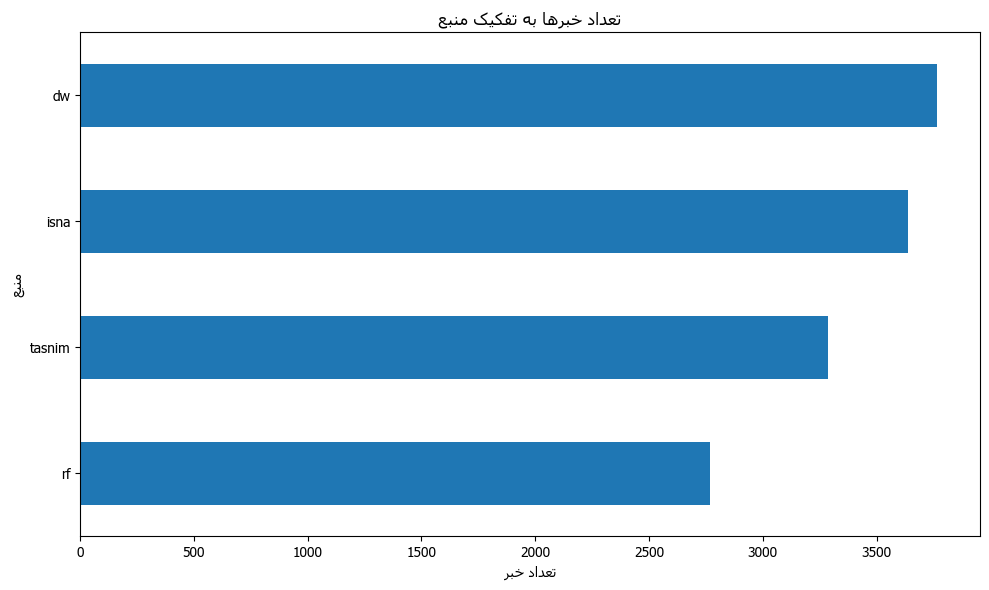

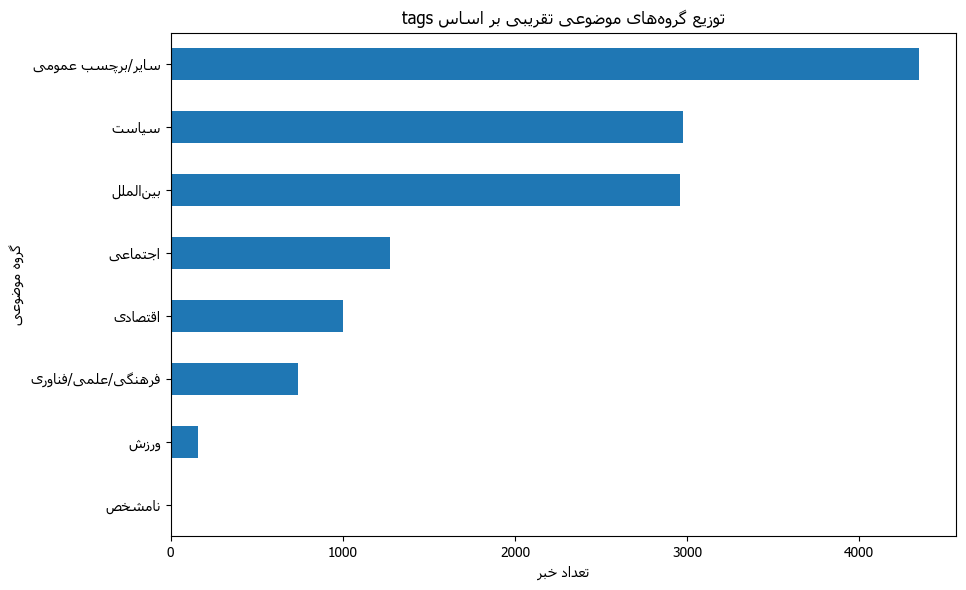

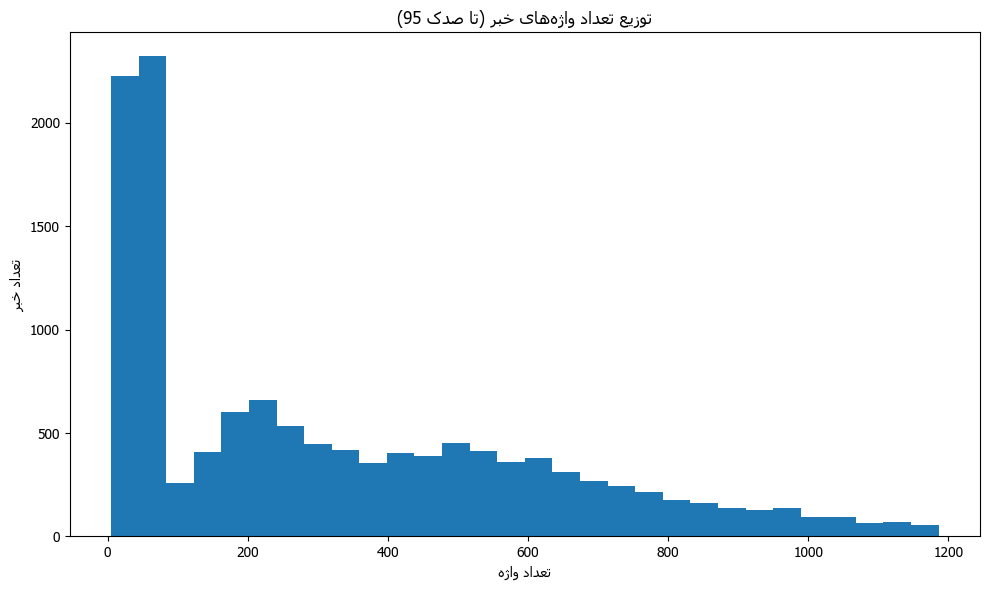

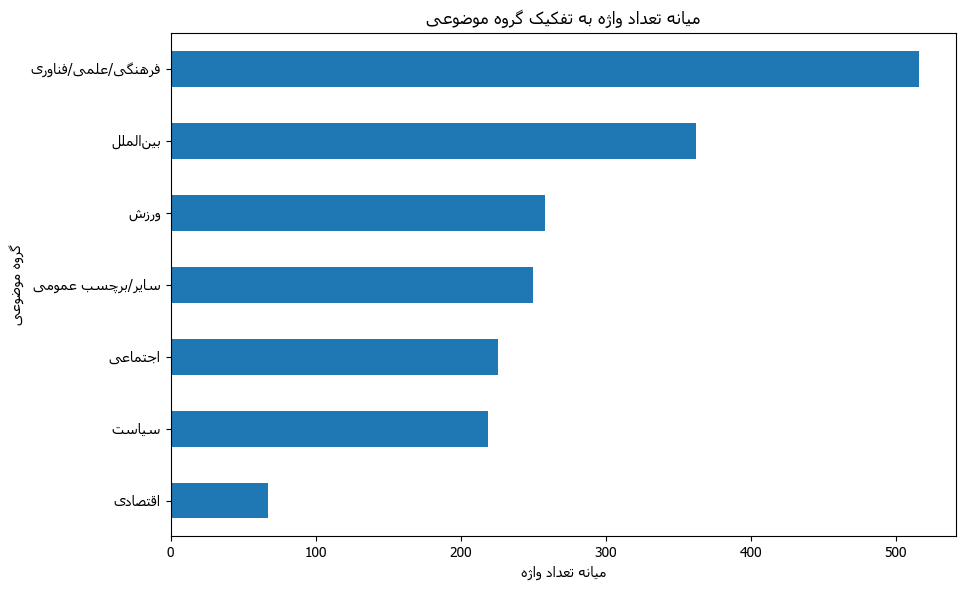

وضعیت نمودارها: موفق


In [16]:
# نمودار ۱: تعداد خبرها به تفکیک منبع
if "site" in df.columns:
    counts = df["source_for_analysis"].value_counts()
    ax = counts.sort_values().plot(kind="barh", title="تعداد خبرها به تفکیک منبع")
    ax.set_xlabel("تعداد خبر")
    ax.set_ylabel("منبع")
    plt.tight_layout()
    fix_persian_axis(ax)
    plt.savefig(CHART_DIR / "01_news_by_source.png", dpi=160, bbox_inches="tight")
    plt.show()

# نمودار ۲: توزیع گروه موضوعی
ax = df["topic_group"].value_counts().sort_values().plot(
    kind="barh", title="توزیع گروه‌های موضوعی تقریبی بر اساس tags"
)
ax.set_xlabel("تعداد خبر")
ax.set_ylabel("گروه موضوعی")
plt.tight_layout()
fix_persian_axis(ax)
plt.savefig(CHART_DIR / "02_news_by_topic_group.png", dpi=160, bbox_inches="tight")
plt.show()

# نمودار ۳: توزیع تعداد واژه‌ها
p95 = max(1, df["word_count"].quantile(0.95))
ax = df.loc[df["word_count"] <= p95, "word_count"].plot(
    kind="hist", bins=30, title="توزیع تعداد واژه‌های خبر (تا صدک 95)"
)
ax.set_xlabel("تعداد واژه")
ax.set_ylabel("تعداد خبر")
plt.tight_layout()
fix_persian_axis(ax)
plt.savefig(CHART_DIR / "03_word_count_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# نمودار ۴: میانه تعداد واژه به تفکیک گروه موضوعی
# گروه «نامشخص» حذف می‌شود چون تعداد نمونه‌اش بسیار کم است و می‌تواند گمراه‌کننده باشد.
median_words = (
    df.loc[df["topic_group"].ne("نامشخص")]
    .groupby("topic_group")["word_count"]
    .median()
    .sort_values()
)
ax = median_words.plot(kind="barh", title="میانه تعداد واژه به تفکیک گروه موضوعی")
ax.set_xlabel("میانه تعداد واژه")
ax.set_ylabel("گروه موضوعی")
plt.tight_layout()
fix_persian_axis(ax)
plt.savefig(CHART_DIR / "04_median_words_by_topic.png", dpi=160, bbox_inches="tight")
plt.show()

stage_status["نمودارها"] = "موفق"
print("وضعیت نمودارها:", stage_status["نمودارها"])

## 7. واژه‌های پرتکرار با حذف واژه‌های عمومی

,واژه,تعداد تکرار
0,ایران,29905
1,کرونا,26689
2,آمریکا,16422
3,ویروس,12103
4,جمهوری,9626
5,اسلامی,9226
6,بیماری,9195
7,ماه,8100
8,آلمان,8055
9,وزیر,7504


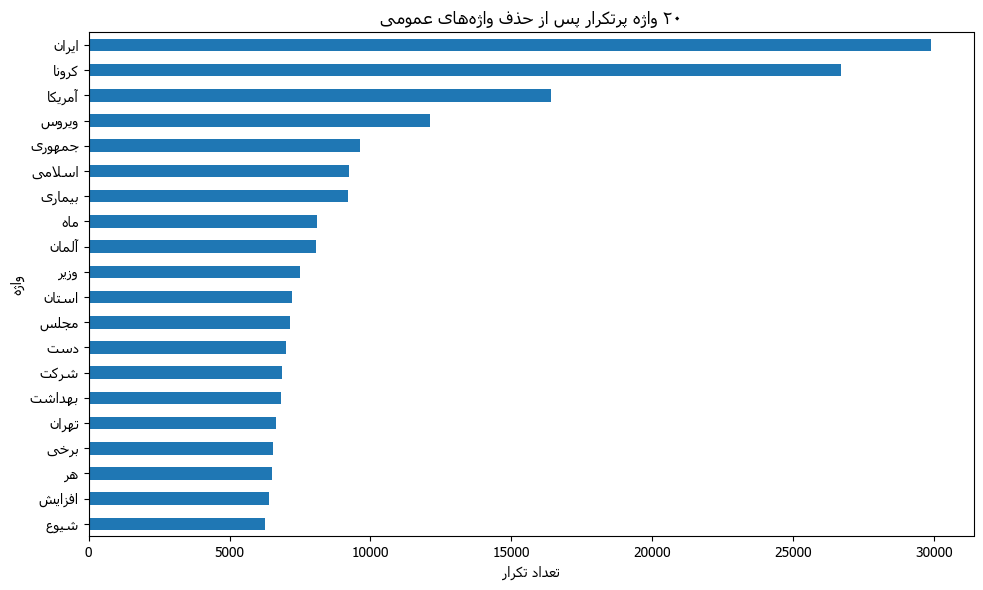

In [17]:
analyzer = NewsAnalyzer(df, stopwords=PERSIAN_STOPWORDS)

top_words = analyzer.top_words(n=20)
display(top_words)
top_words.to_csv(OUTPUT_DIR / "top_20_words.csv", index=False, encoding="utf-8-sig")

# نمودار
top_words_chart = top_words.sort_values("تعداد تکرار").copy()
if not RTL_AVAILABLE:
    top_words_chart["برچسب نمودار"] = [f"Term {i}" for i in range(1, len(top_words_chart) + 1)]
    chart_label_column = "برچسب نمودار"
else:
    chart_label_column = "واژه"

ax = top_words_chart.plot(
    x=chart_label_column,
    y="تعداد تکرار",
    kind="barh",
    legend=False,
    title="۲۰ واژه پرتکرار پس از حذف واژه‌های عمومی",
)
ax.set_xlabel("تعداد تکرار")
ax.set_ylabel("واژه")
plt.tight_layout()
fix_persian_axis(ax)
plt.savefig(CHART_DIR / "05_top_20_words.png", dpi=160, bbox_inches="tight")
plt.show()

if not RTL_AVAILABLE:
    print("راهنمای Term 1..20 در top_20_words.csv؛ برای نمودار فارسی، bidi نصب کن.")

## 8. مقایسه واژه‌ها در دو گروه موضوعی

In [18]:
# توابع قدیمی رو حذف کردم و از analyzer استفاده می‌کنم
selected_groups = [
    g for g in df["topic_group"].value_counts().index
    if g not in ["سایر/برچسب عمومی", "نامشخص"]
]

comparison_df = analyzer.top_words_by_group(group_col="topic_group", n=10)
comparison_df = comparison_df[comparison_df["گروه موضوعی"].isin(selected_groups)].reset_index(drop=True)

display(comparison_df)
comparison_df.to_csv(OUTPUT_DIR / "top_words_by_topic.csv", index=False, encoding="utf-8-sig")
print("گروه‌های مقایسه‌شده:", ", ".join(selected_groups))

,گروه موضوعی,واژه,تعداد تکرار
0,سیاست,ایران,7680
1,سیاست,آمریکا,4205
2,سیاست,کرونا,4141
3,سیاست,مجلس,4070
4,سیاست,اسلامی,3914
5,سیاست,شورای,2664
6,سیاست,جمهور,2482
7,سیاست,جمهوری,2116
8,سیاست,اقتصادی,2078
9,سیاست,تاکید,2077


گروه‌های مقایسه‌شده: سیاست, بین‌الملل, اجتماعی, اقتصادی, فرهنگی/علمی/فناوری, ورزش


## 9. واژه‌های متمایز هر منبع با TF-IDF

TF-IDF در اینجا فقط برای استخراج واژه‌های شاخص هر منبع به‌کار می‌رود؛ مدل پیش‌بینی یا یادگیری ماشین ساخته نمی‌شود. برای کاهش اثر تفاوت حجم منابع، واژه‌های شاخص از میانگین وزن TF-IDF اسناد هر منبع استخراج می‌شوند.

In [19]:
try:
    import sklearn
    from sklearn.feature_extraction.text import TfidfVectorizer

    tfidf_input = df.loc[df["full_text"].fillna("").str.strip().ne("")].copy()
    tfidf_input["source_for_tfidf"] = tfidf_input["source_for_analysis"]
    tfidf_input_docs = len(tfidf_input)
    tfidf_sources = sorted(tfidf_input["source_for_tfidf"].dropna().unique())

    # ترکیب stopwordهای پایه + boilerplate + نام منابع
    source_name_tokens = set()
    for source_name in tfidf_sources:
        source_name_tokens.update(word_tokenize(str(source_name)))

    tfidf_stopword_set = (
        set(PERSIAN_STOPWORDS)
        | TFIDF_BOILERPLATE
        | source_name_tokens
    )

    def tfidf_tokenizer(text):
        return filter_tokens(word_tokenize(str(text)), tfidf_stopword_set)

    tfidf_token_lists = tfidf_input["full_text"].map(tfidf_tokenizer)
    tfidf_tokenized_docs = int(tfidf_token_lists.map(bool).sum())

    tfidf_rows = []
    if len(tfidf_sources) >= 2 and tfidf_input_docs > 0:
        vectorizer = TfidfVectorizer(
            tokenizer=tfidf_tokenizer,
            preprocessor=None,
            token_pattern=None,
            lowercase=False,
            min_df=3,
            max_features=8000,
            stop_words=None,
            sublinear_tf=True,
        )
        tfidf_matrix = vectorizer.fit_transform(tfidf_input["full_text"])
        terms = vectorizer.get_feature_names_out()
        has_features = tfidf_matrix.getnnz(axis=1) > 0
        tfidf_feature_docs = int(has_features.sum())
        tfidf_feature_input = tfidf_input.loc[has_features].copy()
        tfidf_feature_matrix = tfidf_matrix[has_features]

        for source_name in tfidf_sources:
            source_mask = tfidf_feature_input["source_for_tfidf"].eq(source_name).to_numpy()
            other_mask = ~source_mask
            if not source_mask.any() or not other_mask.any():
                continue
            source_scores = tfidf_feature_matrix[source_mask].mean(axis=0).A1
            other_scores = tfidf_feature_matrix[other_mask].mean(axis=0).A1
            contrast = source_scores - other_scores
            source_text = " ".join(tfidf_feature_input.loc[source_mask, "full_text"].tolist())
            source_counts = Counter(tfidf_tokenizer(source_text))
            eligible = [i for i, term in enumerate(terms) if source_counts.get(term, 0) >= 3]
            ranked = sorted(eligible, key=lambda i: contrast[i], reverse=True)[:15]
            for rank, term_idx in enumerate(ranked, 1):
                tfidf_rows.append({
                    "منبع": source_name,
                    "رتبه": rank,
                    "واژه متمایزتر": terms[term_idx],
                    "میانگین TF-IDF در منبع": round(float(source_scores[term_idx]), 6),
                    "میانگین TF-IDF سایر منابع": round(float(other_scores[term_idx]), 6),
                    "اختلاف منبع با سایر منابع": round(float(contrast[term_idx]), 6),
                    "تعداد واژه در متن‌های منبع": int(source_counts[terms[term_idx]]),
                })

        tfidf_terms_df = pd.DataFrame(tfidf_rows)
        display(tfidf_terms_df)
        tfidf_terms_df.to_csv(
            OUTPUT_DIR / "tfidf_distinctive_terms_by_source.csv",
            index=False,
            encoding="utf-8-sig",
        )
        tfidf_status = "موفق" if not tfidf_terms_df.empty else "اجرا شد اما واژه واجد شرایط پیدا نشد"
        print(
            f"TF-IDF: {tfidf_status}; اسناد ورودی={tfidf_input_docs:,}; "
            f"دارای توکن={tfidf_tokenized_docs:,}; دارای ویژگی={tfidf_feature_docs:,}; "
            f"منابع={len(tfidf_sources)}; واژگان={len(terms):,}; sklearn={sklearn.__version__}"
        )
    else:
        tfidf_tokenized_docs = tfidf_feature_docs = 0
        terms = []
        tfidf_terms_df = pd.DataFrame()
        tfidf_status = "ناموفق: اسناد یا منابع کافی نیست"
        print("TF-IDF اجرا نشد:", tfidf_status)
except ImportError as exc:
    tfidf_terms_df = pd.DataFrame()
    tfidf_input_docs = tfidf_tokenized_docs = tfidf_feature_docs = 0
    tfidf_sources = []
    terms = []
    tfidf_status = f"ناموفق: وابستگی نصب نیست ({exc})"
    print("TF-IDF اجرا نشد:", tfidf_status, "| نصب: pip install scikit-learn")

stage_status["TF-IDF"] = tfidf_status

relative_frequency_df = analyzer.relative_frequency_by_source(n=20)
display(relative_frequency_df)
relative_frequency_df.to_csv(
    OUTPUT_DIR / "relative_word_frequency_by_source.csv",
    index=False,
    encoding="utf-8-sig",
)

,منبع,رتبه,واژه متمایزتر,میانگین TF-IDF در منبع,میانگین TF-IDF سایر منابع,اختلاف منبع با سایر منابع,تعداد واژه در متن‌های منبع
0,dw,1,فارسی,0.039313,0.000352,0.038961,5693
1,dw,2,آلمان,0.031517,0.002187,0.029330,7621
2,dw,3,جمهوری,0.026127,0.010976,0.015151,6164
3,dw,4,ترامپ,0.018529,0.005840,0.012690,3798
4,dw,5,دست,0.020990,0.008977,0.012013,3890
5,dw,6,شرکت,0.018676,0.007291,0.011385,4159
6,dw,7,اروپا,0.014970,0.004061,0.010909,2682
7,dw,8,کشورهای,0.017203,0.006443,0.010760,2848
8,dw,9,مارس,0.010760,0.000582,0.010179,977
9,dw,10,حدود,0.016132,0.005996,0.010136,2410


TF-IDF: موفق; اسناد ورودی=13,457; دارای توکن=13,457; دارای ویژگی=13,457; منابع=4; واژگان=8,000; sklearn=1.6.1


,منبع,واژه,تعداد,کل واژه‌های پس از فیلتر,فراوانی به‌ازای 10000 واژه
0,dw,ایران,16426,1368746,120.008
1,dw,کرونا,14278,1368746,104.314
2,dw,آمریکا,9494,1368746,69.363
3,dw,آلمان,7621,1368746,55.679
4,dw,ویروس,7290,1368746,53.260
...,...,...,...,...,...
75,tasnim,جدید,303,94094,32.202
76,tasnim,انقلاب,281,94094,29.864
77,tasnim,تولید,278,94094,29.545
78,tasnim,تهران,277,94094,29.439


## 10. آمار طول متن و جدول‌های نهایی

In [20]:
word_stats = df["word_count"].describe(percentiles=[.25, .5, .75, .95]).to_frame("تعداد واژه")
display(word_stats)
print(f"میانگین تعداد واژه در هر خبر: {df['word_count'].mean():.2f}")
print(f"میانه تعداد واژه در هر خبر: {df['word_count'].median():.0f}")
print(f"درصد خبرهای زیر 100 واژه: {(df['word_count'] < 100).mean()*100:.2f}%")
print(f"درصد خبرهای بیش از 1000 واژه: {(df['word_count'] > 1000).mean()*100:.2f}%")

source_topic = pd.crosstab(
    df["source_for_analysis"], df["topic_group"], normalize="index"
).mul(100).round(1)
display(source_topic)
source_topic.to_csv(OUTPUT_DIR / "source_topic_percent.csv", encoding="utf-8-sig")

p99 = df["word_count"].quantile(0.99)
outlier_cols = [c for c in ["title", "site", "word_count", "link"] if c in df.columns]
long_news_examples = (
    df.loc[df["word_count"] >= p99, outlier_cols]
    .sort_values("word_count", ascending=False)
    .head(10)
)
print(f"آستانه صدک 99 تعداد واژه: {p99:.0f}")
display(long_news_examples)


all_tokens = [t for tokens in df["tokens"] for t in tokens]
top20_raw = [
    w for w, _ in Counter([t for t in all_tokens if len(t) > 1]).most_common(20)
]
top20_filtered = top_words["واژه"].tolist()
common_top20 = len(set(top20_raw) & set(top20_filtered))
print(f"تعداد واژه‌های مشترک در Top-20 خام و پس از stopword: {common_top20} از 20")

,تعداد واژه
count,13457.000000
mean,406.271383
std,533.438564
min,5.000000
25%,53.000000
50%,259.000000
75%,578.000000
95%,1186.000000
max,12313.000000


میانگین تعداد واژه در هر خبر: 406.27
میانه تعداد واژه در هر خبر: 259
درصد خبرهای زیر 100 واژه: 34.40%
درصد خبرهای بیش از 1000 واژه: 7.59%


topic_group,اجتماعی,اقتصادی,بین‌الملل,سایر/برچسب عمومی,سیاست,فرهنگی/علمی/فناوری,نامشخص,ورزش
source_for_analysis,,,,,,,,
dw,0.0,3.7,42.4,45.0,0.0,8.2,0.0,0.8
isna,20.0,8.1,2.2,4.9,54.2,7.8,0.0,2.7
rf,7.1,1.4,8.5,71.7,10.5,0.4,0.1,0.3
tasnim,10.6,16.1,31.8,14.9,21.7,4.2,0.0,0.7


آستانه صدک 99 تعداد واژه: 2419


,title,site,word_count,link
7654,بازخوانی گفت‌وگوی صمیمانه رهبر انقلاب با جمعی ...,isna,12313,https://www.isna.ir/news/99011708494/بازخوانی-...
7510,آخرین اخبار سیل در 13 استان/ راه ارتباطی ۱۴۴ ر...,isna,9669,https://www.isna.ir/news/99010401479/آخرین-اخب...
7507,آخرین اخبار سیل در 13 استان/ افزایش جانباختگان...,isna,9666,https://www.isna.ir/news/99010401479/آخرین-اخب...
10120,وضعیت بورس، سهام عدالت، قرارداد ویلموتس، تغییر...,isna,9578,https://www.isna.ir/news/99061410185/وضعیت-بور...
7511,"آخرین اخبار سیل در 13 استان/ مردم مظلوم ""جازمو...",isna,8800,https://www.isna.ir/news/99010401479/آخرین-اخب...
8691,استقلال سیاسی و افزایش اقتدار، تنها راه باقی م...,isna,8085,https://www.isna.ir/news/99032113708/استقلال-س...
7508,آخرین اخبار سیل در 13 استان/افزایش جانباختگان ...,isna,7863,https://www.isna.ir/news/99010401479/آخرین-اخب...
10454,سردار کارگر: اصل بر غیرمحرمانه بودن اسناد دفاع...,isna,7340,https://www.isna.ir/news/99070402750/سردار-کار...
8292,پایان لاریجانیسم؟,isna,7056,https://www.isna.ir/news/99023022122/پایان-لار...
7757,وحدت کلمه، بدون اغماض از خطاها و خطاکاران سیاس...,isna,6491,https://www.isna.ir/news/99012514152/وحدت-کلمه...


تعداد واژه‌های مشترک در Top-20 خام و پس از stopword: 2 از 20


## 11. یافته‌های مبتنی بر داده

### داده چطور بود
۱۳٬۴۵۷ خبر از چهار منبع. هفت ستون. صفر ردیف کاملاً تکراری. ۵۷ تا خانهٔ خالی که همه‌شون توی `image` و `tags` بودن. `site` هم هیچ مقدار خالی نداشت.

### هر منبع چقدر سهم داشت
تقریباً متعادل بود:
- dw: ۳٬۷۶۶ (۲۸٪)
- isna: ۳٬۶۳۶ (۲۷٪)
- tasnim: ۳٬۲۸۸ (۲۴.۴٪)
- rf: ۲٬۷۶۷ (۲۰.۶٪)

هیچ منبعی اکثریت مطلق نداشت، که برای مقایسه خبر خوبه.

### خبرها چقدر بلند بودن
میانگین ۴۰۶ واژه، میانه ۲۵۹ واژه. فاصله بین این دو زیاده، یعنی چند تا خبر خیلی بلند (مثل خبرهای سیل و بازخوانی سخنرانی) میانگین رو بالا کشیدن. میانه عدد صادقانه‌تریه. حدود یک‌سوم خبرها (۳۴.۴٪) زیر ۱۰۰ واژه‌ان و ۷.۶٪ بالای ۱۰۰۰ واژه.

### گروه‌بندی موضوعی
بزرگ‌ترین گروه، «سایر/برچسب عمومی» با ۳۲.۳٪. بعدش سیاست (۲۲.۱٪) و بین‌الملل (۲۲٪). اجتماعی ۹.۵٪، اقتصادی ۷.۵٪، فرهنگی ۵.۵٪ و ورزش ۱.۲٪.

گروه «سایر» رو نباید یه موضوع حساب کرد. توش بایگانی و ایران و استان‌ها و آلمان هست — یعنی برچسب‌های عمومی، نه موضوع.

### واژه‌های پرتکرار
بعد از حذف stopwordهای عمومی (که چند بار لیستش رو کامل‌تر کردم چون اولش واژه‌های پرتکرار مثل «اند» و «باید» توش می‌موندن)، این واژه‌ها بیشتر اومدن: ایران، کرونا، آمریکا، ویروس، جمهوری، اسلامی، بیماری.

اسم رسانه‌ها (دویچه، ایسنا، تسنیم) رو هم از لیست حذف کردم تا توی Top-20 نیان. اعداد دقیق توی فایل `top_20_words.csv` هست.

### TF-IDF
هر منبع واژه‌های مخصوص خودش رو داره. چند نمونه:
- **dw:** آلمان، اروپا، ترامپ، فارسی، بحران
- **isna:** رییس، جلسه، تاکید، شرایط، دکتر
- **rf:** ایران، کرونا، بازداشت، زندان، شنبه، آقای
- **tasnim:** عراق، لبنان، فلسطین، صهیونیستی، مقاومت، مجلس

فهرست کامل توی فایل `tfidf_distinctive_terms_by_source.csv` هست.

ولی این فقط یه تفاوت واژگانیه. نمی‌شه گفت «dw طرفدار فلان موضوعه» یا «isna جهت‌گیری خاصی داره». بخشی از این تفاوت‌ها از تفاوت موضوعی ترکیب خبر‌هاست، بخشی از سبک نوشتن. برای ادعای سبک تحریریه یا رابطه علّی، این تحلیل کافی نیست.

### محدودیت‌ها
- تاریخ معتبر نداشتیم، پس تحلیل زمانی نکردم.
- گروه‌بندی موضوعی از tags تقریبیه. فایل نمونه‌ها برای بازبینی دستی ذخیره شد (`topic_group_manual_audit_sample.csv`). تا کسی نمونه‌ها رو چک نکنه، دقت این گروه‌بندی تأییدشده نیست.
- stopwordها مقدماتی‌ان. اگه لیست عوض بشه، Top-20 هم عوض می‌شه.
- `category_news.csv` ادغام نشد چون کلید مشترک نداشت.
- گروه «سایر» یکدست نیست.

## 12. خروجی‌ها و قابلیت تکرار

In [22]:
print("فایل‌های خروجی:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print("-", path.as_posix())

فایل‌های خروجی:
- outputs/.ipynb_checkpoints/analysis_corrected_persian-checkpoint.ipynb
- outputs/charts/01_news_by_source.png
- outputs/charts/02_news_by_topic_group.png
- outputs/charts/03_word_count_distribution.png
- outputs/charts/04_median_words_by_topic.png
- outputs/charts/05_top_20_words.png
- outputs/cleaned_news.csv
- outputs/cleaning_test_results.csv
- outputs/relative_word_frequency_by_source.csv
- outputs/source_counts.csv
- outputs/source_topic_percent.csv
- outputs/tfidf_distinctive_terms_by_source.csv
- outputs/top_20_words.csv
- outputs/top_words_by_topic.csv
- outputs/topic_group_counts.csv
- outputs/topic_group_manual_audit_sample.csv
